# 04 · Forecasting and trading

Can the first five minutes of market activity predict the next five—and help us make better trading decisions?

This notebook brings the team’s research together: build price and spread forecasts, compare models, then test a simple trading rule after costs.

The notebook has two parts. **The snapshot tables at the top** are the saved results of the full-data runs on all 112 stocks, including the expanded LightGBM models. **The full analysis below them** was run in this notebook on all 112 stocks, so every table and figure there comes from that run. The two LightGBM sections (5.2 and 5.3) were switched off to keep the run to about an hour; their results are in the snapshot tables. The benchmark windows were not scored.

Explore the work behind this study: [data exploration](00_data_exploration.ipynb), [Swarnendu’s mid-price forecasting](01_midprice_forecasting.ipynb), [Francis’s spread models](02_spread_models.ipynb), and [Nhi’s widening-event classifier](03_spread_widening_events.ipynb).

## Snapshot of the saved results

These tables read the saved files in [`results/`](../results/README.md).


In [1]:
# Snapshot: saved result of the full-data run (all 112 stocks), saved in results/metrics/forecast_accuracy.csv
from pathlib import Path
import pandas as pd
from IPython.display import display
published_root = next(p for p in (Path.cwd(), Path.cwd().parent)
                      if (p / "results/run_manifest.json").is_file())
display(pd.read_csv(published_root / "results/metrics/forecast_accuracy.csv"))


,model,MAE,RMSE,R2,R2 low-activity stocks,R2 mid-activity stocks,R2 high-activity stocks,R2 min-spread-bound,median per-stock R2,RMSE gain vs zero,RMSE gain vs stock mean,RMSE gain vs persistence,target
0,zero,15.416941,24.779282,-0.000097,-0.000142,-0.000053,-0.000112,-0.000055,-0.000201,0.000000,0.000142,0.000000,price
1,stock mean,15.425793,24.782803,-0.000381,-0.000583,-0.000277,-0.000295,-0.000334,-0.000477,-0.000142,0.000000,-0.000142,price
2,persistence,15.416941,24.779282,-0.000097,-0.000142,-0.000053,-0.000112,-0.000055,-0.000201,0.000000,0.000142,0.000000,price
3,ridge,15.047016,24.007978,0.061194,0.064437,0.054172,0.066922,0.050638,0.064251,0.031127,0.031265,0.031127,price
4,HGB,15.165495,24.270303,0.040566,0.046772,0.033743,0.042570,0.034542,0.042443,0.020541,0.020680,0.020541,price
5,selected,15.047016,24.007978,0.061194,0.064437,0.054172,0.066922,0.050638,0.064251,0.031127,0.031265,0.031127,price
6,zero,0.125741,0.179152,-0.041275,-0.035101,-0.046859,-0.049554,-0.044944,-0.047755,0.000000,-0.021784,0.109455,spread
7,stock mean,0.124888,0.175332,0.002650,0.001133,0.000274,0.007584,0.009423,-0.000564,0.021319,0.000000,0.128441,spread
8,persistence,0.146215,0.201171,-0.312966,-0.403386,-0.363607,-0.002553,0.253277,-0.357421,-0.122908,-0.147369,0.000000,spread
9,ridge,0.109988,0.147837,0.290933,0.268573,0.291803,0.342116,0.445699,0.278303,0.174797,0.156821,0.265119,spread


In [2]:
# Snapshot: saved result of the full-data run (all 112 stocks), saved in results/metrics/upgraded_cv.csv
from pathlib import Path
import pandas as pd
from IPython.display import display
published_root = next(p for p in (Path.cwd(), Path.cwd().parent)
                      if (p / "results/run_manifest.json").is_file())
display(pd.read_csv(published_root / "results/metrics/upgraded_cv.csv"))


,target,section 5 selected head R2,upgraded model R2,relative gain,inputs
0,spread,0.348418,0.380387,0.091754,131
1,price,0.061194,0.069969,0.143389,131


Spread development tests whether market information and nonlinear models add forecasting skill. The expanded model adds trade/spread-path inputs and more context; the price and spread tasks remain distinct.

![Forecast accuracy and trading value](../results/figures/figure1_accuracy_vs_value.png)

### From forecast skill to trading value

The more predictable spread target does not improve the particular spread-filter policy tested here. The policy tables and clustered bootstrap intervals show its incremental contribution alongside the price-only policy.

In [3]:
# Snapshot: saved result of the full-data run (all 112 stocks), saved in results/metrics/trading_summary.csv
from pathlib import Path
import pandas as pd
from IPython.display import display
published_root = next(p for p in (Path.cwd(), Path.cwd().parent)
                      if (p / "results/run_manifest.json").is_file())
display(pd.read_csv(published_root / "results/metrics/trading_summary.csv"))


,policy,opportunities,entries,completed,unresolved,trade frequency,net bps per trade,net bps per opportunity,win rate,5th pct trade bps,worst trade bps
0,cash,343144.0,0.0,0.0,0.0,0.000000,NaN,0.00000,NaN,NaN,NaN
1,price only,343144.0,21322.0,21322.0,0.0,0.062137,5.126717,0.31856,0.564628,-37.085087,-285.495904
2,price + spread,343144.0,21322.0,21322.0,0.0,0.062137,5.126717,0.31856,0.564628,-37.085087,-285.495904


In [4]:
# Snapshot: saved result of the full-data run (all 112 stocks), saved in results/metrics/trading_bootstrap.csv
from pathlib import Path
import pandas as pd
from IPython.display import display
published_root = next(p for p in (Path.cwd(), Path.cwd().parent)
                      if (p / "results/run_manifest.json").is_file())
display(pd.read_csv(published_root / "results/metrics/trading_bootstrap.csv"))


,comparison,mean_bps,ci_low,ci_high,resamples,cluster,cost_bps_per_side
0,price + spread minus price only,0.00000,0.000000,0.000000,2000,time_id,0.5
1,price only minus cash,0.31856,0.211673,0.436664,2000,time_id,0.5
2,price + spread minus cash,0.31856,0.211673,0.436664,2000,time_id,0.5


### Robustness evidence

The signal must also survive changes in execution, cost and market context. The full walkthrough below exposes each research question; these tables show two of the checks from the full-data run.

In [5]:
# Snapshot: saved result of the full-data run (all 112 stocks), saved in results/metrics/stress_placebo.csv
from pathlib import Path
import pandas as pd
from IPython.display import display
published_root = next(p for p in (Path.cwd(), Path.cwd().parent)
                      if (p / "results/run_manifest.json").is_file())
display(pd.read_csv(published_root / "results/metrics/stress_placebo.csv"))


,inputs,price R2,trades,net bps per trade,per opportunity,ci_low,ci_high
0,as built,0.061209,21324,5.123032,0.318361,0.211571,0.436587
1,market lagged 30 s,0.046637,16881,4.700401,0.231237,0.134392,0.337846
2,market shuffled across windows,-0.002508,16,-46.762382,-0.002180,-0.004522,-0.000377
3,own-stock inputs only,-0.000679,5,-62.586595,-0.000912,-0.003275,0.001019


In [6]:
# Snapshot: saved result of the full-data run (all 112 stocks), saved in results/metrics/stress_concentration.csv
from pathlib import Path
import pandas as pd
from IPython.display import display
published_root = next(p for p in (Path.cwd(), Path.cwd().parent)
                      if (p / "results/run_manifest.json").is_file())
display(pd.read_csv(published_root / "results/metrics/stress_concentration.csv"))


,trim,"rule, net bps per opportunity","always long at the mid, no costs"
0,all windows,0.318560,0.243653
1,drop own best 5% of windows,-0.120555,-1.237855
2,drop 5% largest |market move|,0.059954,0.286569


## Full analysis

The cells below run the whole analysis from the raw data on all 112 stocks: rebuilding the order books, training the models and testing the trading rules. Every output below comes from that run. The LightGBM sections (5.2 and 5.3) were switched off (`RUN_UPGRADED = False`) because they add about 3.5 hours; their results are in the snapshot tables above.


## 0. Setup

Runs locally or in Colab. Data comes from the Kaggle competition
[`optiver-realized-volatility-prediction`](https://www.kaggle.com/competitions/optiver-realized-volatility-prediction/data)
(accept the competition rules on Kaggle first). Set `DATA_DIR` below, or the `OBF_DATA_DIR`
environment variable, to the extracted folder that contains `train.csv`, `book_train.parquet/` and
`trade_train.parquet/`. In Colab, the next cell clones the repository, installs the requirements and,
if `DATA_DIR` is empty, downloads the data with a `KAGGLE_API_TOKEN` stored in Colab Secrets.

In [7]:
import os, sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/Erdos-Projects/fall-2026-short-horizon-forecasting"
DATA_DIR = os.environ.get("OBF_DATA_DIR", "")      # e.g. "/path/to/optiver-realized-volatility-prediction"
CONFIG = "configs/default.yaml"                     # "configs/smoke.yaml" for a quick 3-stock test

if IN_COLAB:
    if not Path("fall-2026-short-horizon-forecasting").exists():
        !git clone -q {REPO_URL}
    %cd fall-2026-short-horizon-forecasting
    %pip install -q -r requirements.txt
    %pip install -q -e .
    if not DATA_DIR:
        from google.colab import userdata
        import kagglehub
        os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
        DATA_DIR = "/content/data/optiver-realized-volatility-prediction"
        kagglehub.competition_download("optiver-realized-volatility-prediction", output_dir=DATA_DIR)
else:
    root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    os.chdir(root)
    sys.path.insert(0, str(root / "src"))

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from obforecast.config import Timing, load_config
from obforecast.data import ParquetSource, check_layout, resolve_data_dir, select_stocks
from obforecast.book import build_tables
from obforecast import pipeline

cfg = load_config(CONFIG)
timing = Timing.from_config(cfg)
data_dir = resolve_data_dir(DATA_DIR or None, cfg)
layout = check_layout(data_dir)
source = ParquetSource(data_dir)
stock_ids = select_stocks(layout["book_stocks"], cfg["run"]["stocks"])
print(f"run label: {cfg['run']['label']} | data: {data_dir} | stocks used: {len(stock_ids)} of {layout['train_stocks']}")
print({k: v for k, v in layout.items() if k not in ("book_stocks",)})

SCORE_BENCHMARK = False       # set True only for the single, final benchmark run (section 9)
RUN_UPGRADED = False          # True runs sections 5.2/5.3 (LightGBM); adds about 3.5 hours on the full data

run label: full | data: /content/optdata | stocks used: 112 of 112
{'train_rows': 428932, 'train_stocks': 112, 'train_time_ids': 3830, 'book_folders': 112, 'trade_folders': 112, 'book_matches_train': True, 'trade_matches_train': True, 'missing': {'book': [], 'trade': []}}


## 1. Question, timing and hypotheses

Each sample is one stock in one 10-minute window. Features use seconds 0–299; the decision is taken
right after second 299; the simulated trade buys one share at the ask at second 300 (robustness:
302, 305, 310) and sells at the bid at second 599.

| | Hypothesis | Tested in |
|---|---|---|
| H1 | The spread change is predictable beyond stock averages and persistence. | §5, §9 |
| H2 | The price change is predictable, mostly through the market (other stocks). | §5, §7, §8 |
| H3 | A price forecast clears the cost of crossing the spread often enough to earn a positive net return. | §6, §8, §9 |
| H4 | Using the spread forecast as a filter improves the tested trading rule. | §6, §7 |

Any of these can come out negative. This is a simulation; nothing connects to a broker.

## 2. Data and book reconstruction

`build_tables` returns three tables keyed by `(stock_id, time_id)`: **features** (seconds 0–299:
spread level and trend, minimum-spread proxies, WAP volatility, recent returns and book tilt, quote
activity and age, depth and imbalance), **outcomes** (the two targets and the quotes the simulator
needs; never model inputs) and **quality** rows.

In [9]:
# One pass over each stock's book: features (seconds 0..299), outcomes, data quality.
# Cached by obforecast.run under cache/ when you use the command line; here we build directly.
feats, outs, quality, invalid = build_tables(source, stock_ids, timing)
d = pipeline.prepare(feats, outs, cfg)   # legacy benchmark split + outer grouped folds
print(d.split_info)

  built 20/112 stocks (0.5 min)


  built 40/112 stocks (0.9 min)


  built 60/112 stocks (1.3 min)


  built 80/112 stocks (1.8 min)


  built 100/112 stocks (2.2 min)


  built 112/112 stocks (2.5 min)


{'recipe': 'numpy default_rng(0).choice(sorted time_ids, 20%)', 'n_windows': 3830, 'n_benchmark': 766, 'source': 'regenerated from recipe', 'matches_recipe': True, 'dev_windows': 3064, 'dev_rows': 343144, 'bench_windows': 766, 'bench_rows': 85788, 'outer_fold_windows': {0: 613, 1: 613, 2: 613, 3: 613, 4: 612}}


## 3. Validation design and model inputs

1. **Group by window.** All stocks of a `time_id` share a fold (stocks in a window share a market move).
2. **Nest every choice.** Heads and trading rules are picked on inner folds and scored once on an outer
   fold they never saw.
3. **Legacy benchmark.** 766 windows (seed-0 recipe; identifiers saved to `results/splits/`) are set
   aside until §9. These windows were **previously examined** by earlier team experiments, including
   price models on a different split (`archive/README.md`), so they are a consistency check, not an
   untouched test.

Model inputs (47): 30 first-half features in 7 families, 4 stock-relative versions (training-fold
stock means), 11 leave-one-out market means and 2 relative-to-market inputs. The upgraded models of
§5.2 use 131 inputs; the full list is in `results/metrics/feature_inventory.csv`.

In [10]:
from obforecast.features import FEATURES, family, feature_inventory
inv = feature_inventory()
print(f"baseline inputs: {inv.baseline_47.sum()} | upgraded inputs: {inv.upgraded_131.sum()}")
display(pd.Series([family(c) for c in FEATURES]).value_counts().rename("baseline inputs per family").to_frame())

baseline inputs: 47 | upgraded inputs: 131


,baseline inputs per family
spread,14
price,9
volatility,6
activity,6
depth,5
imbalance,4
min_spread,3


## 5. Forecasts: baselines and two simple models (H1, H2)

Baselines: zero change, the stock's training-fold mean, and persistence (price: zero; spread: the
last-60 s mean spread persists). Heads: median imputation + scaling + ridge (α from the config) and one
fixed `HistGradientBoostingRegressor`. In each outer fold the head with the lowest inner out-of-fold
RMSE is selected per target, refit on the outer training fold and scored on the outer validation fold.
The trading rules of §6 are chosen in the same loop.

In [11]:
cv = pipeline.nested_cv(d, cfg, timing)
display(cv.selections)

outer fold 1/5: heads {'price': 'ridge a=1', 'spread': 'HGB'} | rules {'price only': (2.0, inf), 'price + spread': (2.0, inf)} | 3.6 min


outer fold 2/5: heads {'price': 'ridge a=100', 'spread': 'HGB'} | rules {'price only': (2.0, inf), 'price + spread': (2.0, inf)} | 3.4 min


outer fold 3/5: heads {'price': 'ridge a=100', 'spread': 'HGB'} | rules {'price only': (2.0, inf), 'price + spread': (2.0, inf)} | 3.4 min


outer fold 4/5: heads {'price': 'ridge a=1', 'spread': 'HGB'} | rules {'price only': (2.0, inf), 'price + spread': (2.0, inf)} | 3.4 min


outer fold 5/5: heads {'price': 'ridge a=1', 'spread': 'HGB'} | rules {'price only': (2.0, inf), 'price + spread': (2.0, inf)} | 3.4 min


,fold,price head,spread head,price ridge alpha,spread ridge alpha,price only: margin_bps,price + spread: margin_bps,price only: tau,price + spread: tau,price only: inner trades,price + spread: inner trades,minutes
0,0,ridge a=1,HGB,ridge a=1,ridge a=10,2.0,2.0,inf,inf,16323,16323,3.598885
1,1,ridge a=100,HGB,ridge a=100,ridge a=10,2.0,2.0,inf,inf,18055,18055,3.377313
2,2,ridge a=100,HGB,ridge a=100,ridge a=10,2.0,2.0,inf,inf,17184,17184,3.425657
3,3,ridge a=1,HGB,ridge a=1,ridge a=100,2.0,2.0,inf,inf,17806,17806,3.442656
4,4,ridge a=1,HGB,ridge a=1,ridge a=10,2.0,2.0,inf,inf,17156,17156,3.404851


### 5.1 Forecast accuracy (outer folds)

RMSE is in each target's own units; do not compare it across targets. Historical reference values
from the archived notebook's saved output are spread R² ≈ 0.3484 and price R² ≈ 0.0612 (development,
HGB and ridge selected). The committed full-data run reproduced these rounded values; the published tables above give the exact scores.

In [12]:
acc = pd.concat([pipeline.forecast_table(t, d, cv.oof) for t in ("price", "spread")])
display(acc.set_index(["target", "model"]).round(4))
cal = pd.concat([pipeline.calibration(t, d, cv.oof) for t in ("price", "spread")])
from obforecast import figures
figures.calibration_figure(cal, Path(cfg["run"]["output_dir"]) / "figures" / "calibration.png")
display(cal.round(3))

MAE     RMSE      R2  R2 low-activity stocks  \
target model                                                           
price  zero         15.4169  24.7793 -0.0001                 -0.0001   
       stock mean   15.4258  24.7828 -0.0004                 -0.0006   
       persistence  15.4169  24.7793 -0.0001                 -0.0001   
       ridge        15.0470  24.0080  0.0612                  0.0644   
       HGB          15.1655  24.2703  0.0406                  0.0468   
       selected     15.0470  24.0080  0.0612                  0.0644   
spread zero          0.1257   0.1792 -0.0413                 -0.0351   
       stock mean    0.1249   0.1753  0.0027                  0.0011   
       persistence   0.1462   0.2012 -0.3130                 -0.4034   
       ridge         0.1100   0.1478  0.2909                  0.2686   
       HGB           0.1034   0.1417  0.3484                  0.3114   
       selected      0.1034   0.1417  0.3484                  0.3114   

                    R2 mid-activity stocks  R2 high-activity stocks  \
target model                                                          
price  zero                        -0.0001                  -0.0001   
       stock mean                  -0.0003                  -0.0003   
       persistence                 -0.0001                  -0.0001   
       ridge                        0.0542                   0.0669   
       HGB                          0.0337                   0.0426   
       selected                     0.0542                   0.0669   
spread zero                        -0.0469                  -0.0496   
       stock mean                   0.0003                   0.0076   
       persistence                 -0.3636                  -0.0026   
       ridge                        0.2918                   0.3421   
       HGB                          0.3328                   0.4658   
       selected                     0.3328                   0.4658   

                    R2 min-spread-bound  median per-stock R2  \
target model                                                   
price  zero                     -0.0001              -0.0002   
       stock mean               -0.0003              -0.0005   
       persistence              -0.0001              -0.0002   
       ridge                     0.0506               0.0643   
       HGB                       0.0345               0.0424   
       selected                  0.0506               0.0643   
spread zero                     -0.0449              -0.0478   
       stock mean                0.0094              -0.0006   
       persistence               0.2533              -0.3574   
       ridge                     0.4457               0.2783   
       HGB                       0.6237               0.3300   
       selected                  0.6237               0.3300   

                    RMSE gain vs zero  RMSE gain vs stock mean  \
target model                                                     
price  zero                    0.0000                   0.0001   
       stock mean             -0.0001                   0.0000   
       persistence             0.0000                   0.0001   
       ridge                   0.0311                   0.0313   
       HGB                     0.0205                   0.0207   
       selected                0.0311                   0.0313   
spread zero                    0.0000                  -0.0218   
       stock mean              0.0213                   0.0000   
       persistence            -0.1229                  -0.1474   
       ridge                   0.1748                   0.1568   
       HGB                     0.2090                   0.1917   
       selected                0.2090                   0.1917   

                    RMSE gain vs persistence  
target model                                  
price  zero                           0.0000  
       stock mean                    -0.0001  
       per

,decile,pred,actual,se,n,target
0,0,-10.806,-9.742,0.209,34315,price
1,1,-4.116,-3.125,0.124,34314,price
2,2,-2.250,-1.416,0.103,34314,price
3,3,-1.130,-0.575,0.095,34315,price
4,4,-0.207,-0.084,0.093,34314,price
5,5,0.668,0.471,0.095,34314,price
6,6,1.603,1.186,0.096,34315,price
7,7,2.788,1.565,0.106,34314,price
8,8,4.618,3.112,0.120,34314,price
9,9,11.181,11.045,0.202,34315,price


### 5.2 Upgraded models

Same folds, everything fitted on training folds: the 31 extra first-half inputs (spread path, depth
trend, trade prints), more market context, stock target statistics and a categorical stock id; the
spread uses LightGBM averaged over seeds and the price a 50/50 blend of a Huber LightGBM and a ridge.
**The trading results in §6–§9 use the §5 models, not these.**

In [13]:
from obforecast.extra import extra_stock
if RUN_UPGRADED:
    extra = pd.concat([extra_stock(s, source.load("book", s), source.load("trade", s), timing) for s in stock_ids],
                      ignore_index=True)
    up = pipeline.upgraded_cv(d, extra, cv, cfg)
    display(up["table"].round(4))
else:
    print("Skipped in this run (RUN_UPGRADED = False). The saved LightGBM results are in the snapshot tables at the top of this notebook.")


Skipped in this run (RUN_UPGRADED = False). The saved LightGBM results are in the snapshot tables at the top of this notebook.


### 5.3 Drivers and unseen stocks

(a) Mean absolute LightGBM contribution per input (models fitted on folds 2–5, explained on a sample
of fold 1). (b) Spread skill on stocks **and** windows never seen in training (stock group k ×
window fold k), compared on the same rows with a model that has seen those stocks.

In [14]:
if RUN_UPGRADED:
    chk = pipeline.upgraded_checks(d, up["dev_x"], cfg)
    top = chk["drivers"].sort_values("mean_abs_contribution", ascending=False).groupby("target").head(12)
    display(top.round(5))
    u = chk["unseen"].pivot(index="fold", columns="setting", values="spread R2")
    u.loc["mean"] = u.mean()
    display(u.round(3))
else:
    print("Skipped in this run (RUN_UPGRADED = False). The saved LightGBM results are in the snapshot tables at the top of this notebook.")


Skipped in this run (RUN_UPGRADED = False). The saved LightGBM results are in the snapshot tables at the top of this notebook.


## 6. Trading simulation (H3, H4)

| Policy | Enter when |
|---|---|
| Cash | never |
| Price only | forecast `y_price` > current relative spread + 2 × cost per side + margin |
| Price + spread | the same, and forecast `y_spread ≤ τ` |

Buy one share at the ask at 300 and sell at the bid at 599, with a proportional cost per side
(0, 0.5, 1 bp; 0.5 is the reference). Crossing the quotes already pays the spread, so it is not
subtracted again. A leg without a quote or size is *unresolved* and earns 0 rather than being
dropped. The main metric is **net bps per opportunity** (no trade = 0). Prices are normalised and
`time_id`s are shuffled, so there is no dollar P&L, equity curve, Sharpe ratio or drawdown.

In [15]:
tr = pipeline.trading(d, cv, cfg, timing)
display(tr["summary"].set_index("policy").round(3))
display(tr["bootstrap"].round(4))
print(tr["window_t"])

,opportunities,entries,completed,unresolved,trade frequency,net bps per trade,net bps per opportunity,win rate,5th pct trade bps,worst trade bps
policy,,,,,,,,,,
cash,343144.0,0.0,0.0,0.0,0.000,NaN,0.000,NaN,NaN,NaN
price only,343144.0,21322.0,21322.0,0.0,0.062,5.127,0.319,0.565,-37.085,-285.496
price + spread,343144.0,21322.0,21322.0,0.0,0.062,5.127,0.319,0.565,-37.085,-285.496


,comparison,mean_bps,ci_low,ci_high,resamples,cluster,cost_bps_per_side
0,price + spread minus price only,0.0000,0.0000,0.0000,2000,time_id,0.5
1,price only minus cash,0.3186,0.2117,0.4367,2000,time_id,0.5
2,price + spread minus cash,0.3186,0.2117,0.4367,2000,time_id,0.5


{'price only window-level t': 2.7813448539989314, 'traded windows': 1025}


### 6.1 Sensitivity

(1) Fixed decisions under each cost, later entry and stale-ask filters; (2) rules re-selected under
each cost from the same inner forecasts (a different question, so a separate table); (3) stock groups.

In [16]:
sens = pipeline.sensitivity(d, cv, tr["ENTER"], cfg, timing)
cols = ["entries", "net bps per trade", "net bps per opportunity", "win rate"]
display(sens["fixed"].set_index(["policy", "check"])[cols].round(3))
display(sens["retuned"].set_index(["cost bp/side", "policy"])[cols].round(3))
display(sens["groups"].set_index(["policy", "group"])[["opportunities"] + cols].round(3))

entries  \
policy         check                                           
price only     cost 0.0 bp/side                        21322   
               cost 0.5 bp/side                        21322   
               cost 1.0 bp/side                        21322   
               entry delay +2 s                        21322   
               entry delay +5 s                        21322   
               entry delay +10 s                       21322   
               skip entries on asks older than 30 s    21322   
               skip entries on asks older than 2 s     20548   
price + spread cost 0.0 bp/side                        21322   
               cost 0.5 bp/side                        21322   
               cost 1.0 bp/side                        21322   
               entry delay +2 s                        21322   
               entry delay +5 s                        21322   
               entry delay +10 s                       21322   
               skip entries on asks older than 30 s    21322   
               skip entries on asks older than 2 s     20548   

                                                     net bps per trade  \
policy         check                                                     
price only     cost 0.0 bp/side                                  6.127   
               cost 0.5 bp/side                                  5.127   
               cost 1.0 bp/side                                  4.126   
               entry delay +2 s                                  4.900   
               entry delay +5 s                                  4.573   
               entry delay +10 s                                 4.179   
               skip entries on asks older than 30 s              5.127   
               skip entries on asks older than 2 s               5.207   
price + spread cost 0.0 bp/side                                  6.127   
               cost 0.5 bp/side                                  5.127   
               cost 1.0 bp/side                                  4.126   
               entry delay +2 s                                  4.900   
               entry delay +5 s                                  4.573   
               entry delay +10 s                                 4.179   
               skip entries on asks older than 30 s              5.127   
               skip entries on asks older than 2 s               5.207   

                                                     net bps per opportunity  \
policy         check                                                           
price only     cost 0.0 bp/side                                        0.381   
               cost 0.5 bp/side                                        0.319   
               cost 1.0 bp/side                                        0.256   
               entry delay +2 s                                        0.304   
               entry delay +5 s                                        0.284   
               entry delay +10 s                                       0.260   
               skip entries on asks older than 30 s                    0.319   
               skip entries on asks older than 2 s                     0.312   
price + spread cost 0.0 bp/side                                        0.381   
               cost 0.5 bp/side                                        0.319   
               cost 1.0 bp/side                                        0.256   
               entry delay +2 s                                        0.304   
               entry delay +5 s                                        0.284   
               entry delay +10 s                                       0.260   
               skip entries on asks older than 30 s                    0.319   
               skip entries on asks older than 2 s                     0.312   

                                                     win rate  
policy         check                                          

entries  net bps per trade  \
cost bp/side policy                                       
0.0          price only        33958              3.954   
             price + spread    33958              3.954   
0.5          price only        21322              5.127   
             price + spread    21322              5.127   
1.0          price only        15855              5.533   
             price + spread    15855              5.533   

                             net bps per opportunity  win rate  
cost bp/side policy                                             
0.0          price only                        0.391     0.544  
             price + spread                    0.391     0.544  
0.5          price only                        0.319     0.565  
             price + spread                    0.319     0.565  
1.0          price only                        0.256     0.563  
             price + spread                    0.256     0.563

opportunities  entries  \
policy         group                                          
price only     low activity                 116418     2796   
               mid activity                 113359     6342   
               high activity                113367    12184   
               min-spread-bound              64343     6462   
               not min-spread-bound         278801    14860   
price + spread low activity                 116418     2796   
               mid activity                 113359     6342   
               high activity                113367    12184   
               min-spread-bound              64343     6462   
               not min-spread-bound         278801    14860   

                                     net bps per trade  \
policy         group                                     
price only     low activity                      5.083   
               mid activity                      4.783   
               high activity                     5.315   
               min-spread-bound                  4.814   
               not min-spread-bound              5.263   
price + spread low activity                      5.083   
               mid activity                      4.783   
               high activity                     5.315   
               min-spread-bound                  4.814   
               not min-spread-bound              5.263   

                                     net bps per opportunity  win rate  
policy         group                                                    
price only     low activity                            0.122     0.553  
               mid activity                            0.268     0.557  
               high activity                           0.571     0.571  
               min-spread-bound                        0.483     0.560  
               not min-spread-bound                    0.281     0.567  
price + spread low activity                            0.122     0.553  
               mid activity                            0.268     0.557  
               high activity                           0.571     0.571  
               min-spread-bound                        0.483     0.560  
               not min-spread-bound                    0.281     0.567

## 7. Why the spread forecast does or does not help the tested rule

(a) A direct forecast of the realised crossing cost vs the current spread `q_299` used by the hurdle;
(b) an oracle rule given the exact realised cost (not tradable: if it does not help, no spread forecast
can help **this** rule); (c) a market-only price model (window-mean return forecast × stock beta); (d)
calibration of the price forecast by decile.

In [17]:
why = pipeline.why_spread(d, cv, tr["ENTER"], cfg, timing)
display(why["diagnostics"].round(4)); display(why["policies"].round(4)); display(why["deciles"].round(2))

,quantity,value
0,cost R2 using q_299,0.8060
1,cost R2 ridge forecast,0.8621
2,cost RMSE ridge (bps),2.5545
3,price-forecast RMSE (bps),24.0080
4,price R2 selected (47 inputs),0.0612
5,price R2 market-only,0.0590
6,market-only share of price R2,0.9641


,policy,entries,net bps per trade,net bps per opportunity,minus price only,ci_low,ci_high
0,price only (section 6),21322,5.1267,0.3186,0.000,0.0000,0.0000
1,oracle: exact realised cost,23194,4.6385,0.3135,-0.005,-0.0215,0.0109
2,market-only price model,20924,4.8642,0.2966,-0.022,-0.0481,0.0023


,decile,forecast,realised,net if bought
0,0,-10.81,-9.74,-20.55
1,1,-4.12,-3.13,-10.63
2,2,-2.25,-1.42,-7.89
3,3,-1.13,-0.57,-6.76
4,4,-0.21,-0.08,-6.18
5,5,0.67,0.47,-5.74
6,6,1.60,1.19,-5.12
7,7,2.79,1.57,-5.17
8,8,4.62,3.11,-4.26
9,9,11.18,11.04,0.63


### Figure 1. Forecast accuracy vs trading value

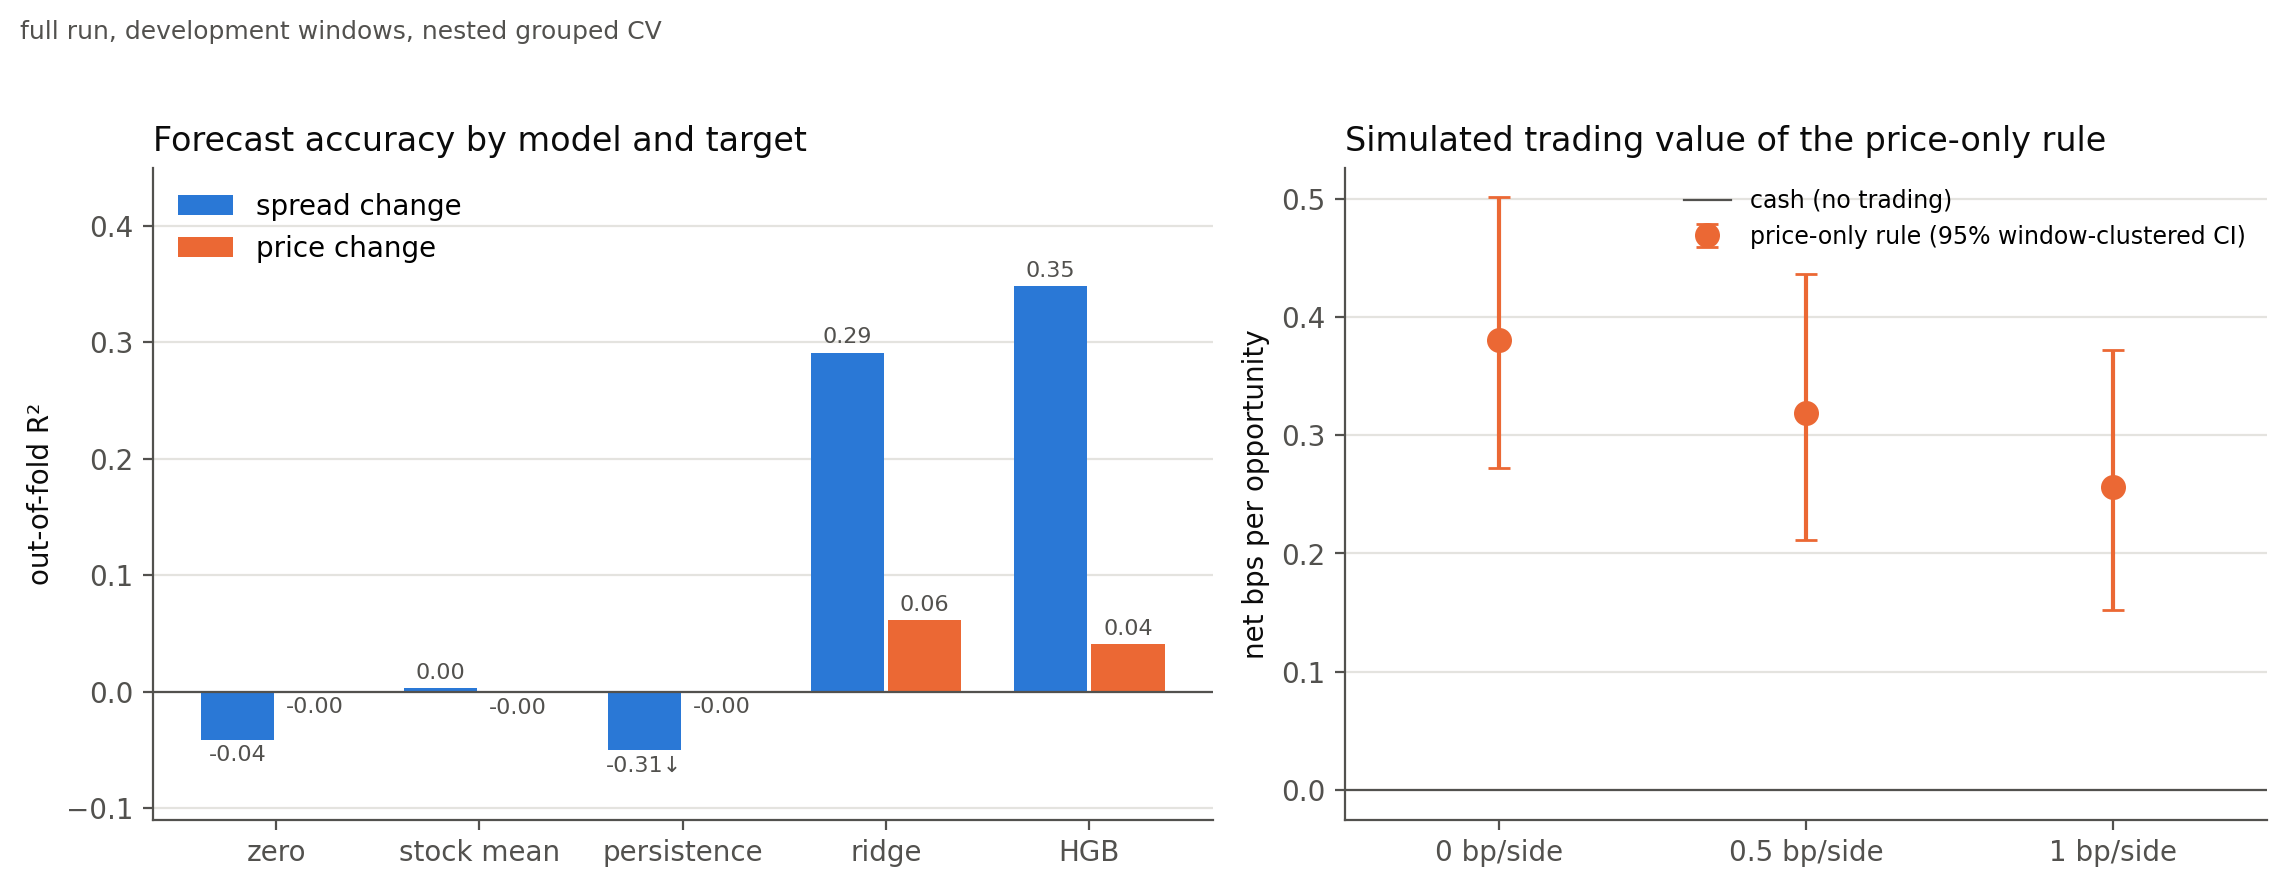

In [18]:
skill = pd.DataFrame({"model": ["zero", "stock mean", "persistence", "ridge", "HGB"]})
for t, col in [("spread", "y_spread"), ("price", "y_price")]:
    skill[t] = [pipeline.r2(d.dev_o[col].to_numpy(), cv.oof[f"{t}: {m}"].to_numpy()) for m in skill.model]
vals = []
for c in cfg["trading"]["cost_scenarios_bps"]:
    po = pipeline.per_opportunity(tr["ENTER"]["price only"], d.dev_o, c, timing)
    m, lo, hi = pipeline.paired_bootstrap(po, np.zeros(len(po)), d.dev_f.time_id.to_numpy(),
                                          cfg["bootstrap"]["resamples"], cfg["bootstrap"]["seed"])
    vals.append({"cost_bps": c, "mean_bps": m, "ci_low": lo, "ci_high": hi})
out = Path(cfg["run"]["output_dir"]) / "figures" / "figure1_accuracy_vs_value.png"
figures.figure1(skill, pd.DataFrame(vals), out, f"{cfg['run']['label']} run, development windows, nested grouped CV")
from IPython.display import Image
Image(str(out))

## 8. Robustness

### 8.1 Feature ablation
One family removed at a time with all of its stock-relative, market and relative versions; fast HGB
on 3 grouped folds, so compare rows within this table only.

In [19]:
display(pipeline.ablation(d, cfg).round(4))

,feature set,price,spread,n_cols,price: R2 loss,spread: R2 loss
0,all features,0.0392,0.3455,47.0,0.0000,0.0000
1,without spread,0.0315,0.2593,33.0,0.0077,0.0861
2,without min_spread,0.0389,0.3454,44.0,0.0003,0.0001
3,without volatility,0.0369,0.3438,41.0,0.0023,0.0017
4,without price,-0.0248,0.3379,38.0,0.0640,0.0076
5,without activity,0.0382,0.3410,41.0,0.0010,0.0045
6,without depth,0.0369,0.3414,42.0,0.0023,0.0041
7,without imbalance,0.0390,0.3445,43.0,0.0001,0.0009
8,only own-stock inputs (no mkt_/rel_),0.0011,0.2935,34.0,0.0381,0.0519
9,only market inputs (mkt_*),0.0328,0.1316,11.0,0.0064,0.2138


### 8.2 Stress tests
(a) When does the gain accrue, and do stale quotes earn more? (b) lagged-by-30 s and shuffled-across-
windows market inputs (placebo), own-stock inputs only; (c) concentration in the best windows, with a
frictionless always-long benchmark trimmed the same way; (d) neighbouring margins and break-even fee.
For speed (b) uses plain grouped CV with a fixed rule, so its "as built" row differs slightly from §6.

In [20]:
from obforecast.extra import path_points
from obforecast.book import KEYS
pts = pd.concat([path_points(s, source.load("book", s), cfg["robustness"]["path_seconds"], timing) for s in stock_ids],
                ignore_index=True)
st = pipeline.stress(d, cv, tr["ENTER"], d.dev_f[KEYS].merge(pts, on=KEYS, how="left"), cfg, timing)
for k, v in st.items():
    print(k); display(v.round(3) if isinstance(v, pd.DataFrame) else v)

accrual


,second,mean mid move since decision (bps)
0,300,0.085
1,302,0.239
2,310,0.854
3,330,2.244
4,360,4.097
5,420,6.869
6,480,8.810
7,540,10.149
8,599,10.684


fresh


,subset,trades,net bps per trade
0,own quote updated at decision second,17862,5.413
1,own quote 1+ s old at decision second,3460,3.648
2,both legs on fresh quotes,13659,6.010


placebo


,inputs,price R2,trades,net bps per trade,per opportunity,ci_low,ci_high
0,as built,0.061,21324,5.123,0.318,0.212,0.437
1,market lagged 30 s,0.047,16881,4.700,0.231,0.134,0.338
2,market shuffled across windows,-0.003,16,-46.762,-0.002,-0.005,-0.000
3,own-stock inputs only,-0.001,5,-62.587,-0.001,-0.003,0.001


... (2 outputs left out)

concentration_info


{'trades': 21322,
 'traded windows': 1025,
 'windows': 3064,
 'share of rule P&L in best 1% of windows': 0.7632494566397213,
 'gross bps per trade (fee 0)': 6.127022891896575,
 'break-even fee bp per side (decisions fixed)': 3.0635114459482873}

margins


,margin_bps,net bps per opportunity
0,0,0.275
1,1,0.311
2,2,0.319
3,3,0.302
4,5,0.259
5,8,0.187


### 8.3 Leakage from a random split
The same HGB scored with folds grouped by window and with random rows. Stock means are learned on
each training fold (the archived notebook learned them once on all development rows).

In [21]:
display(pipeline.leakage_demo(d, cfg).round(3))

,split,price R2,spread R2
0,grouped by window,0.041,0.348
1,random rows,0.179,0.356
2,random / grouped ratio,4.404,1.021


### 8.4 Correctness checks
Key uniqueness and row alignment, group separation (outer and inner), future-data perturbation of
**baseline and upgraded book/trade inputs**, forward-fill boundaries, the flat round trip, cost
monotonicity, price-scale invariance, and the decision function's inputs. The same checks run on
synthetic books in `tests/`.

In [22]:
from obforecast.checks import run_checks
sid = stock_ids[0]
checks = run_checks(feats, outs, d.dev_f, cfg, timing,
                    sample_stock=(sid, source.load("book", sid), source.load("trade", sid)))
display(checks)
assert checks.passed.all(), list(checks.check[~checks.passed])

,check,passed
0,"unique keys, features = outcomes row for row",True
1,no time_id in two folds (outer and inner),True
2,future perturbation: baseline features identical,True
3,future perturbation: targets/fills change,True
4,future perturbation: upgraded book/trade featu...,True
5,price scaling invariance,True
6,no backfill before a window's first quote,True
7,no carry-over between windows,True
8,flat round trip loses exactly the spread,True
9,higher costs never raise profit,True


## 9. Legacy benchmark, scored once

The pipeline is frozen (heads and both policies chosen on inner folds of all development rows, refit
on all development rows) and scored once on the benchmark windows. Unlike the archived notebook, both
policies are selected and scored, so the spread filter is actually tested here. Remember that these
windows were previously examined (§3).

In [23]:
if SCORE_BENCHMARK:
    bench = pipeline.benchmark_run(d, cfg, timing)
    display(bench["skill"].round(4)); display(bench["trading"].round(3)); print(bench["frozen"])
    if RUN_UPGRADED:
        display(pipeline.upgraded_benchmark(d, extra, bench, cfg).round(4))
else:
    print("Benchmark not scored (SCORE_BENCHMARK = False).")

Benchmark not scored (SCORE_BENCHMARK = False).


## 10. Hypotheses, from the computed results

The verdict table below is computed from this run, not written by hand.

In [24]:
s = tr["summary"].set_index("policy"); b = tr["bootstrap"].set_index("comparison")
acc_i = acc.set_index(["target", "model"])
tau_chosen = cv.selections["price + spread: tau"].replace(np.inf, np.nan).notna().sum()
verdicts = pd.DataFrame([
    ("H1 spread predictable", f"selected R2 {acc_i.loc[('spread', 'selected'), 'R2']:.3f} vs stock mean "
     f"{acc_i.loc[('spread', 'stock mean'), 'R2']:.3f} and persistence {acc_i.loc[('spread', 'persistence'), 'R2']:.3f}"),
    ("H2 price predictable", f"selected R2 {acc_i.loc[('price', 'selected'), 'R2']:.3f}; market-only share "
     f"{why['diagnostics'].set_index('quantity').loc['market-only share of price R2', 'value']:.0%}"),
    ("H3 net return after costs", f"price only minus cash {b.loc['price only minus cash', 'mean_bps']:+.3f} bps/opp "
     f"(95% CI {b.loc['price only minus cash', 'ci_low']:+.3f} to {b.loc['price only minus cash', 'ci_high']:+.3f})"),
    ("H4 spread filter improves the tested rule", f"filter chosen in {tau_chosen} of {len(cv.selections)} folds; "
     f"difference {b.loc['price + spread minus price only', 'mean_bps']:+.4f} bps/opp "
     f"(CI {b.loc['price + spread minus price only', 'ci_low']:+.4f} to {b.loc['price + spread minus price only', 'ci_high']:+.4f})"),
], columns=["hypothesis", "evidence (this run)"])
pd.set_option("display.max_colwidth", 200); display(verdicts)

,hypothesis,evidence (this run)
0,H1 spread predictable,selected R2 0.348 vs stock mean 0.003 and persistence -0.313
1,H2 price predictable,selected R2 0.061; market-only share 96%
2,H3 net return after costs,price only minus cash +0.319 bps/opp (95% CI +0.212 to +0.437)
3,H4 spread filter improves the tested rule,filter chosen in 0 of 5 folds; difference +0.0000 bps/opp (CI +0.0000 to +0.0000)


**Limits that apply whatever the numbers say**
* **No time order.** `time_id`s are shuffled, so the same days can appear in every fold and in the
  benchmark; this is not an out-of-time test.
* **Previously examined benchmark.** See §3 and `archive/README.md`.
* **Simplified execution.** One share at the displayed quote; no queue position, market impact,
  latency beyond 10 s or real fee schedule; normalised prices, so no dollar capacity.
* **Concentration.** The effective sample is windows, not trades; check §8.2 for how much of the
  simulated P&L sits in a few windows.
* **Scope of H4.** A negative H4 means the tested spread filter did not improve the tested
  price-hurdle rule; it does not show that spread forecasts cannot improve trading in general.